In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
train = pd.read_csv("train_preprocessed.csv", low_memory=False)
train["Date"] = pd.to_datetime(train["Date"])
print("Shape:", train.shape)

Shape: (1017209, 32)


In [3]:
# Convert Date column to datetime
train["Date"] = pd.to_datetime(train["Date"])

# Select Store 1
store_data = train[train["Store"] == 1].copy()

# Sort by date
store_data = store_data.sort_values("Date")

# Keep only Date and Sales
sales_series = store_data[["Date", "Sales"]].copy()

print("Store 1 data shape:", sales_series.shape)
print(sales_series.head())
print(sales_series.tail())

Store 1 data shape: (942, 2)
              Date  Sales
1016095 2013-01-01      0
1014980 2013-01-02   5530
1013865 2013-01-03   4327
1012750 2013-01-04   4486
1011635 2013-01-05   4997
           Date  Sales
4460 2015-07-27   6102
3345 2015-07-28   5011
2230 2015-07-29   4782
1115 2015-07-30   5020
0    2015-07-31   5263


In [4]:
sales_series = sales_series.set_index("Date")

# Set daily frequency
sales_series = sales_series.asfreq("D")

print("Shape:", sales_series.shape)
print("Missing values:", sales_series.isnull().sum())
print(sales_series.head())

Shape: (942, 1)
Missing values: Sales    0
dtype: int64
            Sales
Date             
2013-01-01      0
2013-01-02   5530
2013-01-03   4327
2013-01-04   4486
2013-01-05   4997


In [5]:
lookback = 30

sales_values = sales_series["Sales"].values

X, y = [], []

for i in range(lookback, len(sales_values)):
    X.append(sales_values[i-lookback:i])
    y.append(sales_values[i])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (912, 30)
y shape: (912,)


In [6]:
split_index = int(len(X) * 0.80)

X_train = X[:split_index]
X_valid = X[split_index:]

y_train = y[:split_index]
y_valid = y[split_index:]

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (729, 30)
X_valid: (183, 30)
y_train: (729,)
y_valid: (183,)


In [7]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(-1, 1))

# Fit only on training data
scaler.fit(X_train.reshape(-1, 1))

# Transform training and validation data
X_train_scaled = scaler.transform(
    X_train.reshape(-1, 1)
).reshape(X_train.shape)

X_valid_scaled = scaler.transform(
    X_valid.reshape(-1, 1)
).reshape(X_valid.shape)

y_train_scaled = scaler.transform(
    y_train.reshape(-1, 1)
).flatten()

y_valid_scaled = scaler.transform(
    y_valid.reshape(-1, 1)
).flatten()

print("Training range:", X_train_scaled.min(), X_train_scaled.max())
print("Validation range:", X_valid_scaled.min(), X_valid_scaled.max())
print("Scaled target range:", y_train_scaled.min(), y_train_scaled.max())

Training range: -1.0 1.0
Validation range: -1.0 0.4307304785894206
Scaled target range: -1.0 1.0


In [8]:
X_train_lstm = X_train_scaled.reshape(
    X_train_scaled.shape[0], 30, 1
)

X_valid_lstm = X_valid_scaled.reshape(
    X_valid_scaled.shape[0], 30, 1
)

print("X_train_lstm:", X_train_lstm.shape)
print("X_valid_lstm:", X_valid_lstm.shape)
print("y_train_scaled:", y_train_scaled.shape)
print("y_valid_scaled:", y_valid_scaled.shape)

X_train_lstm: (729, 30, 1)
X_valid_lstm: (183, 30, 1)
y_train_scaled: (729,)
y_valid_scaled: (183,)


In [9]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout

lstm_model = Sequential([
    Input(shape=(30, 1)),
    LSTM(50),
    Dropout(0.2),
    Dense(1)
])

lstm_model.compile(
    optimizer="adam",
    loss="mean_squared_error"
)

lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

history = lstm_model.fit(
    X_train_lstm,
    y_train_scaled,
    epochs=50,
    batch_size=32,
    validation_data=(X_valid_lstm, y_valid_scaled),
    callbacks=[early_stop],
    shuffle=False,
    verbose=1
)

Epoch 1/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 3s 45ms/step - loss: 0.1894 - val_loss: 0.1574
Epoch 2/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - loss: 0.1853 - val_loss: 0.1547
Epoch 3/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.1811 - val_loss: 0.1527
Epoch 4/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.1810 - val_loss: 0.1508
Epoch 5/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1802 - val_loss: 0.1492
Epoch 6/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1799 - val_loss: 0.1476
Epoch 7/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1768 - val_loss: 0.1464
Epoch 8/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.1768 - val_loss: 0.1469
Epoch 9/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1772 - val_loss: 0.1452
Epoch 10/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1755 - val_loss: 0.1446
Epoch 11/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.1744 - val_loss: 0.1447
Epoch 12/50
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.1

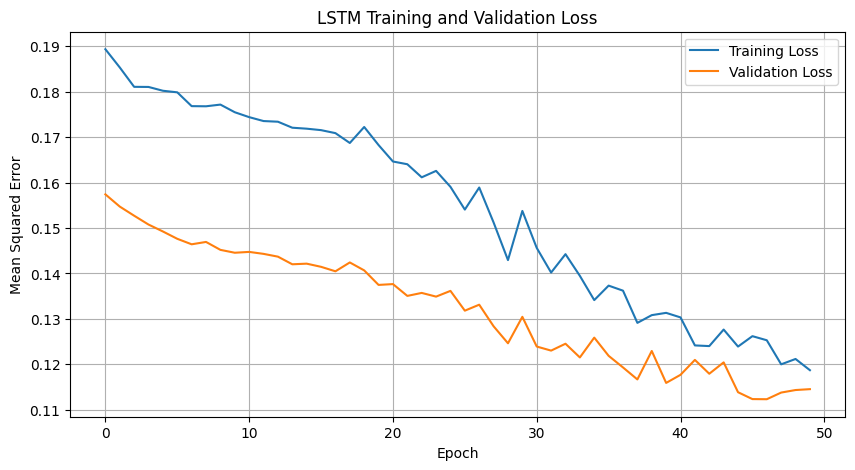

In [11]:
plt.figure(figsize=(10, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error")
plt.legend()
plt.grid(True)

plt.show()

In [12]:
# Generate predictions
y_pred_scaled = lstm_model.predict(X_valid_lstm)

# Convert predictions back to original sales scale
y_pred_lstm = scaler.inverse_transform(
    y_pred_scaled
).flatten()

# Convert actual validation values back to original scale
y_actual_lstm = scaler.inverse_transform(
    y_valid_scaled.reshape(-1, 1)
).flatten()

print("Number of predictions:", len(y_pred_lstm))
print("First 10 actual sales:", y_actual_lstm[:10])
print("First 10 predicted sales:", y_pred_lstm[:10])

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step
Number of predictions: 183
First 10 actual sales: [5577. 5363.    0. 6038. 4901. 4672. 4394. 5022. 4663.    0.]
First 10 predicted sales: [2684.107  1552.8236 1051.3098 4251.533  3850.7844 5002.9214 4174.7983
 3437.1465 2462.4119 1777.2473]


In [13]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae_lstm = mean_absolute_error(
    y_actual_lstm,
    y_pred_lstm
)

rmse_lstm = np.sqrt(
    mean_squared_error(
        y_actual_lstm,
        y_pred_lstm
    )
)

# RMSPE calculated only where actual sales > 0
mask = y_actual_lstm > 0

rmspe_lstm = np.sqrt(
    np.mean(
        ((y_actual_lstm[mask] - y_pred_lstm[mask]) /
         y_actual_lstm[mask]) ** 2
    )
)

print("LSTM MAE:", mae_lstm)
print("LSTM RMSE:", rmse_lstm)
print("LSTM RMSPE:", rmspe_lstm)

LSTM MAE: 1192.4260634125255
LSTM RMSE: 1596.6668390596192
LSTM RMSPE: 0.24010302183976806


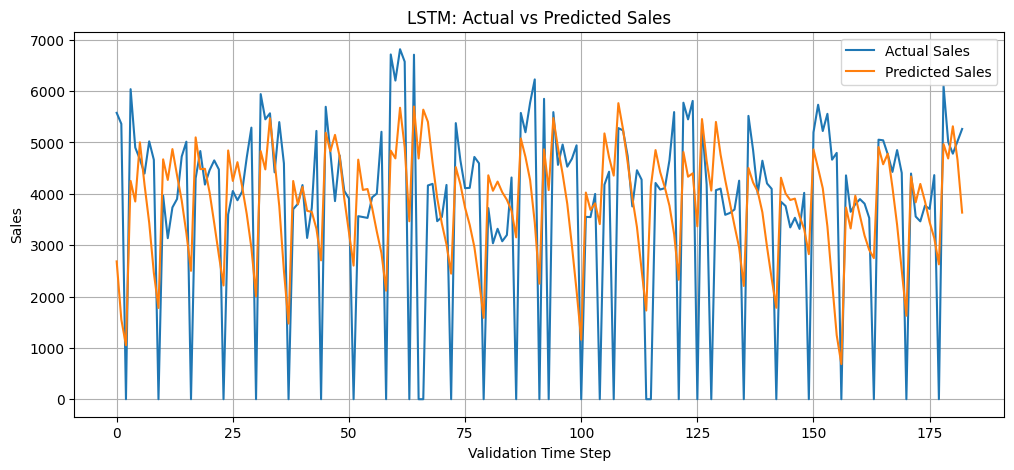

In [14]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_actual_lstm,
    label="Actual Sales"
)

plt.plot(
    y_pred_lstm,
    label="Predicted Sales"
)

plt.title("LSTM: Actual vs Predicted Sales")
plt.xlabel("Validation Time Step")
plt.ylabel("Sales")
plt.legend()
plt.grid(True)

plt.show()

Residual mean: -54.216287915172465
Residual std: 1595.7460916691398
Residual minimum: -5639.064453125
Residual maximum: 3810.1763916015625


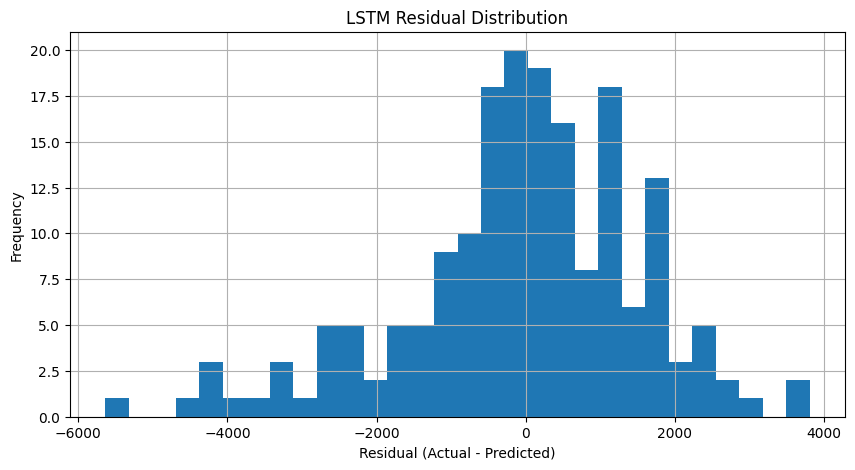

In [15]:
residuals_lstm = y_actual_lstm - y_pred_lstm

print("Residual mean:", residuals_lstm.mean())
print("Residual std:", residuals_lstm.std())
print("Residual minimum:", residuals_lstm.min())
print("Residual maximum:", residuals_lstm.max())

plt.figure(figsize=(10, 5))

plt.hist(residuals_lstm, bins=30)

plt.title("LSTM Residual Distribution")
plt.xlabel("Residual (Actual - Predicted)")
plt.ylabel("Frequency")
plt.grid(True)

plt.show()

In [16]:
import datetime
import pickle

timestamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")

lstm_model_filename = f"lstm_sales_model_{timestamp}.pkl"

with open(lstm_model_filename, "wb") as file:
    pickle.dump(lstm_model, file)

print("LSTM model saved as:", lstm_model_filename)

LSTM model saved as: lstm_sales_model_20261115_112956.pkl


In [17]:
# Load the serialized LSTM model
with open(lstm_model_filename, "rb") as file:
    loaded_lstm_model = pickle.load(file)

# Generate predictions using the loaded model
y_pred_loaded_scaled = loaded_lstm_model.predict(X_valid_lstm)

# Convert back to original sales scale
y_pred_loaded = scaler.inverse_transform(
    y_pred_loaded_scaled
).flatten()

# Verify predictions match
predictions_match = np.allclose(
    y_pred_lstm,
    y_pred_loaded
)

print("Predictions match:", predictions_match)

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
Predictions match: True


In [18]:
# Save the fitted scaler
scaler_filename = f"lstm_sales_scaler_{timestamp}.pkl"

with open(scaler_filename, "wb") as file:
    pickle.dump(scaler, file)

print("Scaler saved as:", scaler_filename)

Scaler saved as: lstm_sales_scaler_20261115_112956.pkl


In [19]:
from google.colab import files

files.download(lstm_model_filename)
files.download(scaler_filename)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>